# Random Forest (owner: Sriniket Deeduvanu)


## Objective

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees to classify buildings into damage grades. It can model nonlinear relationships and interactions between features.

## Hyperparameter Tuning

We compared six configurations by varying the number of trees (`n_estimators`), maximum tree depth (`max_depth`), minimum samples per leaf (`min_samples_leaf`), and class weighting (`class_weight`). All configurations used the same training and validation split and `random_state=42`.

## Results and Model Selection

The best configuration was `n_estimators=100`, `max_depth=None`, `min_samples_leaf=2`, and `class_weight=None`. It achieved a validation micro-F1 of **0.7315 (73.15%)**, outperforming the original configuration (0.6638) and the `main.py` baseline (0.7232).

The smaller-leaf configuration improved validation performance, but its training score (0.8663) is substantially higher than its validation score (0.7315), suggesting some overfitting. We selected it because it achieved the highest validation micro-F1 among the tested configurations.

## Interpretation

The model performs best on damage grade 2, with an F1-score of 0.79. Recall is lower for grades 1 and 3 (0.45 and 0.59), meaning the model misses some buildings in those categories. These class-wise results should be considered alongside the overall score.


In [2]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


Training: Baseline
Training: Shallower
Training: More trees
Training: Smaller leaves
Training: Balanced weights
Training: Current config


,configuration,train_micro_f1,val_micro_f1,train_accuracy,val_accuracy
3,Smaller leaves,0.866304,0.731509,0.866304,0.731509
2,More trees,0.782286,0.724813,0.782286,0.724813
0,Baseline,0.782051,0.723202,0.782051,0.723202
1,Shallower,0.741428,0.707201,0.741428,0.707201
4,Balanced weights,0.741160,0.675083,0.741160,0.675083
5,Current config,0.706619,0.663840,0.706619,0.663840


Selected configuration: {'name': 'Smaller leaves', 'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 2, 'class_weight': None}
Best validation micro-F1: 0.7315
random_forest: micro-F1 = 0.7315
              precision    recall  f1-score   support

           1       0.69      0.45      0.54      5025
           2       0.72      0.86      0.79     29652
           3       0.76      0.59      0.67     17444

    accuracy                           0.73     52121
   macro avg       0.73      0.63      0.66     52121
weighted avg       0.73      0.73      0.72     52121



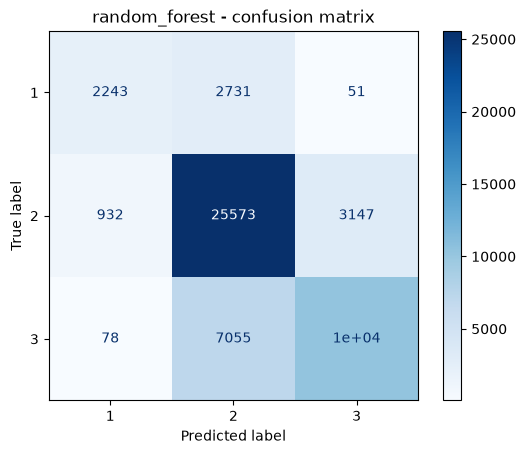

Final validation accuracy: 0.7315
Final training score: 0.8663
Final validation score: 0.7315


In [3]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Small hyperparameter search for Random Forest
configs = [
    {"name": "Baseline", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 5, "class_weight": None},
    {"name": "Shallower", "n_estimators": 100, "max_depth": 20, "min_samples_leaf": 5, "class_weight": None},
    {"name": "More trees", "n_estimators": 200, "max_depth": None, "min_samples_leaf": 5, "class_weight": None},
    {"name": "Smaller leaves", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 2, "class_weight": None},
    {"name": "Balanced weights", "n_estimators": 100, "max_depth": None, "min_samples_leaf": 5, "class_weight": "balanced"},
    {"name": "Current config", "n_estimators": 200, "max_depth": 20, "min_samples_leaf": 4, "class_weight": "balanced"},
]

results = []
best_model = None
best_f1 = -1
best_config = None

for config in configs:
    print(f"Training: {config['name']}")

    model = Pipeline([
        ("preprocessor", build_tree_preprocessor(X_train)),
        ("classifier", RandomForestClassifier(
            n_estimators=config["n_estimators"],
            max_depth=config["max_depth"],
            min_samples_leaf=config["min_samples_leaf"],
            class_weight=config["class_weight"],
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)
    train_f1 = f1_score(y_train, model.predict(X_train), average="micro")
    val_pred = model.predict(X_val)
    val_f1 = f1_score(y_val, val_pred, average="micro")

    results.append({
        "configuration": config["name"],
        "train_micro_f1": train_f1,
        "val_micro_f1": val_f1,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "val_accuracy": accuracy_score(y_val, val_pred),
    })

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_model = model
        best_config = config

results_df = pd.DataFrame(results).sort_values("val_micro_f1", ascending=False)
display(results_df)

print("Selected configuration:", best_config)
print(f"Best validation micro-F1: {best_f1:.4f}")

# Save the best model's evaluation artifacts using the project's evaluator
y_val_pred_rf = best_model.predict(X_val)
rf_f1 = evaluate_model("random_forest", y_val, y_val_pred_rf)

print(f"Final validation accuracy: {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Final training score: {best_model.score(X_train, y_train):.4f}")
print(f"Final validation score: {best_model.score(X_val, y_val):.4f}")